calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


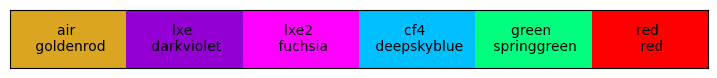

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as FF
from FittingTools.FittingFunctions import *

import FittingTools.PDE_fittingTools as SS

from cycler import cycler


MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

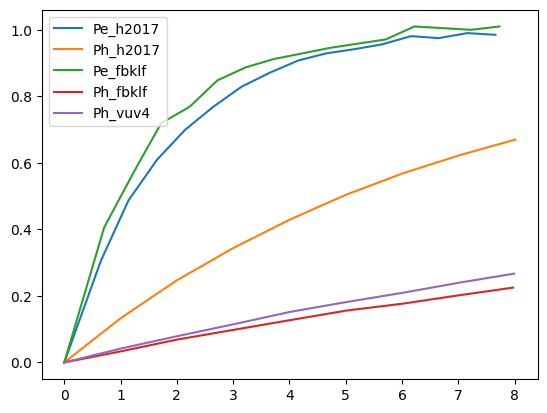

In [3]:
# ATP paper curves
pe_h2017 = np.loadtxt('outputs/giacomo_atpPaper/'+"Pe_h2017.txt", delimiter=',', unpack=True)
ph_h2017 = np.loadtxt('outputs/giacomo_atpPaper/'+"Ph_h2017.txt", delimiter=',', unpack=True)

ph_vuv4 = np.loadtxt('outputs/giacomo_atpPaper/'+"Ph_vuv4.txt", delimiter=',', unpack=True)

pe_fbklf = np.loadtxt('outputs/giacomo_atpPaper/'+"Pe_fbklf.txt", delimiter=',', unpack=True)
ph_fbklf = np.loadtxt('outputs/giacomo_atpPaper/'+"Ph_fbklf.txt", delimiter=',', unpack=True)

plt.plot(pe_h2017[0], pe_h2017[1], label='Pe_h2017')
plt.plot(ph_h2017[0], ph_h2017[1], label='Ph_h2017')
plt.plot(pe_fbklf[0], pe_fbklf[1], label='Pe_fbklf')
plt.plot(ph_fbklf[0], ph_fbklf[1], label='Ph_fbklf')
plt.plot(ph_vuv4[0], ph_vuv4[1], label='Ph_vuv4')

plt.legend()


---- Harry Pe values ----
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}


Text(0, 0.5, 'Pe')

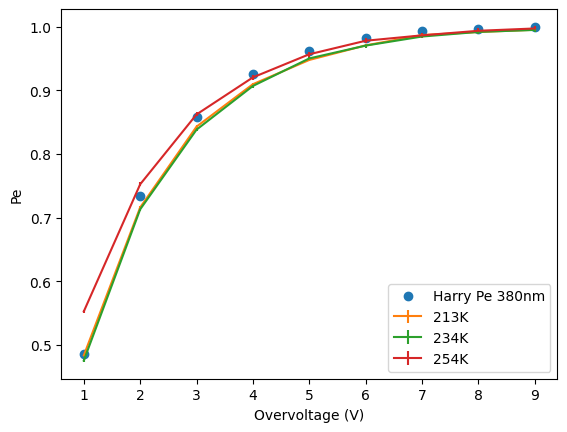

In [4]:
## Harry's 380~nm PE data
## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]

file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryErrorPe = df_pe['Error'].values/df_pe['Raw rate'].values
harryVoltagePE = df_pe['Overvoltage'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}

print("---- Harry Pe values ----")
print(harryPedict)

plt.plot(harryVoltagePE, harryPe, 'o', label='Harry Pe 380nm')
plt.errorbar(overvoltage_213k, pa_213k, yerr=pa_error_213k, fmt='', label='213K')
plt.errorbar(overvoltage_234k, pa_234k, yerr=pa_error_234k, fmt='', label='234K')
plt.errorbar(overvoltage_254k, pa_254k, yerr=pa_error_254k, fmt='', label='254K')
plt.xlabel('Overvoltage (V)')

plt.legend()
plt.ylabel('Pe')

In [5]:
##### Parameterized fit curves #####
## load in new json data
with open("fit_results.json", 'r') as file:
    json_fits = json.load(file)
    
## default global fit result
jsondefault_global = json_fits["HPK_VUV4"]["default_global"]
ve_vuv_defg = json_fits["HPK_VUV4"]["default_global"]["fit_parameters"]["Ve"]
vh_vuv_defg = json_fits["HPK_VUV4"]["default_global"]["fit_parameters"]["Vh"]

ve_vuv_frantag = json_fits["HPK_VUV4"]["franta_global"]["fit_parameters"]["Ve"]
vh_vuv_frantag = json_fits["HPK_VUV4"]["franta_global"]["fit_parameters"]["Vh"]

ve_fbk_defg = json_fits["FBK_LF"]["default_global"]["fit_parameters"]["Ve"]
vh_fbk_defg = json_fits["FBK_LF"]["default_global"]["fit_parameters"]["Vh"]

ve_fbk_frantag = json_fits["FBK_LF"]["franta_global"]["fit_parameters"]["Ve"]
vh_fbk_frantag = json_fits["FBK_LF"]["franta_global"]["fit_parameters"]["Vh"]

df_vuv4_def_nested = pd.read_csv("outputs/HPK_wlen_fits/HPK_Pcurves_default_global_nested.csv")
df_vuv4_franta_nested = pd.read_csv("outputs/HPK_wlen_fits/HPK_Pcurves_franta_global_nested.csv")

df_fbk_def_nested = pd.read_csv("outputs/FBK_wlen_fits/FBK_Pcurves_default_global_nested.csv")
df_fbk_franta_nested = pd.read_csv("outputs/FBK_wlen_fits/FBK_Pcurves_default_franta_nested.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'outputs/HPK_wlen_fits/HPK_Pcurves_default_global_nested.csv'

---
### need to show some stuff

In [ ]:
lw_franta = 4
la_franta = 0.5

ms_paper = 'd'

ms_nested = 's'

errPh_H = 0.15
errPh_VUV4 = 0.73
errPh_FBKL = 0.19

max dif
[1 2 3 4 5 6 7 8 9]
[0.27045517 0.12378422 0.06756195 0.03634751 0.02312003 0.01620788
 0.00848419 0.00637058 0.00467783]


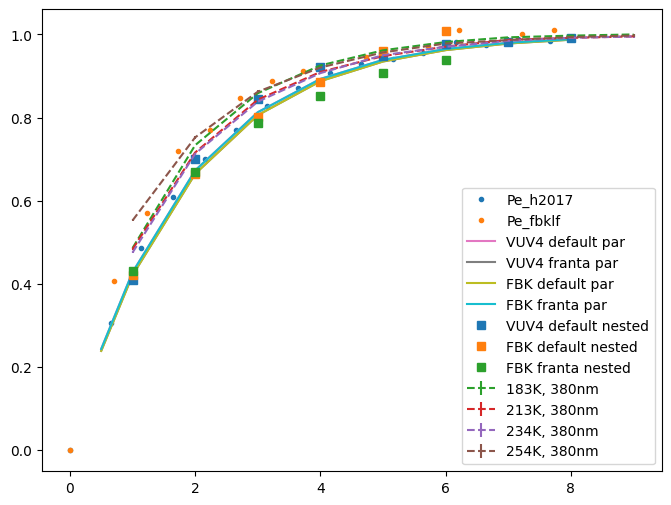

In [ ]:
## compared PE curves
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
x = np.append([0.5], harryVoltagePE[:-1])

# paper
# 380nm
# fits, parameterized
# fits, nested

# from paper
ax.plot(pe_h2017[0], pe_h2017[1], marker = ".", linestyle="none", label='Pe_h2017')
ax.plot(pe_fbklf[0], pe_fbklf[1], marker = ".", linestyle="none", label='Pe_fbklf')

# harry
str_toadd = ", 380nm"
ax.errorbar(harryVoltagePE, harryPe, harryPe*1e-3, linestyle="--", label='183K'+str_toadd)

plt.errorbar(overvoltage_213k, pa_213k, yerr=pa_error_213k, fmt='--', label='213K'+str_toadd)
plt.errorbar(overvoltage_234k, pa_234k, yerr=pa_error_234k, fmt='--', label='234K'+str_toadd)
overvoltage_254k = np.array(overvoltage_254k)
plt.errorbar(overvoltage_254k, pa_254k, yerr=pa_error_254k, fmt='--', label='254K'+str_toadd)

# HPK - parameterized
ax.plot(x, ME.Pcar_parametrized(x, ve_vuv_defg[0], 1.0), label='VUV4 default par')
ax.plot(x, ME.Pcar_parametrized(x, ve_vuv_frantag[0], 1.0), label='VUV4 franta par')

# fbk - parameterized
ax.plot(x, ME.Pcar_parametrized(x, ve_fbk_defg[0], 1.0), label='FBK default par')
ax.plot(x, ME.Pcar_parametrized(x, ve_fbk_frantag[0], 1.0), label='FBK franta par')

# #HPK - nested
ax.plot(df_vuv4_def_nested['overvoltage'].values, df_vuv4_def_nested['pe'].values, marker = "s", linestyle = "None", label='VUV4 default nested')
# ax.plot(df_vuv4_franta_nested['overvoltage'].values, df_vuv4_franta_nested['pe'].values, label='VUV4 franta global nested') ## ignore for bad Ph values

# # # FBK - nested
ax.plot(df_fbk_def_nested['overvoltage'].values, df_fbk_def_nested['pe'].values, marker = "s", linestyle = "None", label='FBK default nested')
ax.plot(df_fbk_franta_nested['overvoltage'].values, df_fbk_franta_nested['pe'].values, marker = "s", linestyle = "None", label='FBK franta nested')

# ax.set_xscale('log')
# ax.set_ylim(0.8, 1.05)
ax.legend()

# percent difference

maxDif = (pa_254k - ME.Pcar_parametrized(overvoltage_254k, ve_fbk_defg[0], 1.0)) / ((pa_254k + ME.Pcar_parametrized(overvoltage_254k, ve_fbk_defg[0], 1.0))/2)

print("max dif")
print(harryVoltagePE)
print(maxDif)

<ValueView eta=1.8279873366239476 Ve=2.2>
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 0.005069                   │              Nfcn = 13               │
│ EDM = 1.22e-07 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬──────────

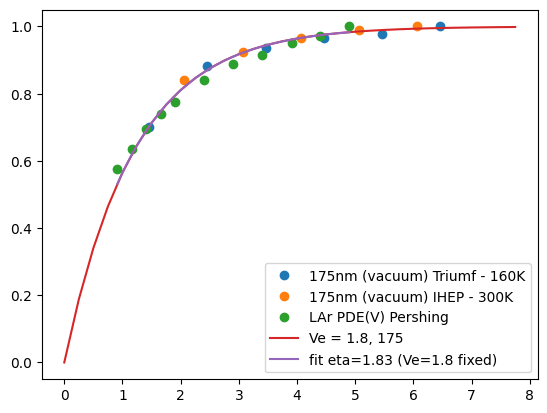

In [ ]:
## load in VUV PDE(V) data which should match Pe(V)

tri_v, tri_pde, ihep_v, ihep_pde = np.loadtxt(os.path.join(LITERATURE_DATA_PATH, "nexo_gallina_performanceNovel", "VUV4_pdeVoltage.csv"), delimiter=",", skiprows=2, unpack=True)
ihep_v = ihep_v[:-1]
ihep_pde = ihep_pde[:-1]

tri_pde = tri_pde/np.max(tri_pde)  # convert to fraction
ihep_pde = ihep_pde/np.max(ihep_pde)

pershing_v, pershing_pde = np.loadtxt(os.path.join(LITERATURE_DATA_PATH,  "pershing_vuvPDE_voltage.csv"), delimiter=",", skiprows=1, unpack=True)
pershing_pde = pershing_pde/np.max(pershing_pde)
# pershing_v *= 0.8

hShift = 0.
plt.plot(tri_v + hShift, tri_pde, label='175nm (vacuum) Triumf - 160K', marker='o', linestyle='None')
plt.plot(ihep_v + hShift, ihep_pde, label='175nm (vacuum) IHEP - 300K', marker='o', linestyle='None')
plt.plot(pershing_v + hShift, pershing_pde, label='LAr PDE(V) Pershing', marker='o', linestyle='None')

# ME.QuantumPe(wlen, pe, 300, 0.75)

def quantumPE_wrapper(volt, wlen, Ve):
  Pe = ME.Pcar_parametrized(volt, Ve, 1.0)
  Qpe = ME.QuantumPe(wlen, Pe, 300, 0.75)
  return Qpe

def quantumPE_toFit(volt, eta, Ve):
  Pe = ME.Pcar_parametrized(volt, Ve, 1.0)
  Qpe = 1-(1 - Pe)**eta
  return Qpe

xtVoltages = np.arange(0, 8, 0.25)
# plt.plot(xtVoltages, ME.Pcar_parametrized(xtVoltages, 1.8, 1.0), linestyle = "-", label='Ve = 1.8')
# plt.plot(xtVoltages, ME.Pcar_parametrized(xtVoltages, 1.6, 1.0), linestyle = "-", label='Ve = 1.6')
# plt.plot(xtVoltages, ME.Pcar_parametrized(xtVoltages, 1.2, 1.0), linestyle = "-", label='Ve = 1.2')
plt.plot(xtVoltages, quantumPE_wrapper(xtVoltages, 175, 1.8), linestyle = "-", label='Ve = 1.8, 175')
# plt.plot(xtVoltages, quantumPE_wrapper(xtVoltages, 128, 1.8), linestyle = "-", label='Ve = 1.8, 128')

# --- concise iminuit fit: fit only eta, fix Ve ---
chisq = lambda eta, Ve: np.sum((quantumPE_toFit(pershing_v, eta, Ve) - pershing_pde)**2)
m = Minuit(chisq, eta=1.8, Ve=2.2);
m.errordef = Minuit.LEAST_SQUARES;
m.limits['eta']=(1.0, 3.0)
m.fixed['Ve']=True;
# m.limits['Ve'] = (1.2, 2.5)
res = m.migrad()
print(res.values)
print(res)
m.hesse()

eta_fit = m.values['eta']
print("fitted eta:", eta_fit)
vfit = np.linspace(pershing_v.min(), pershing_v.max(), 200)

plt.plot(vfit, quantumPE_toFit(vfit, eta_fit, m.values['Ve']), '-', label=f'fit eta={eta_fit:.2f} (Ve=1.8 fixed)')

plt.legend()

NameError: name 'plt' is not defined

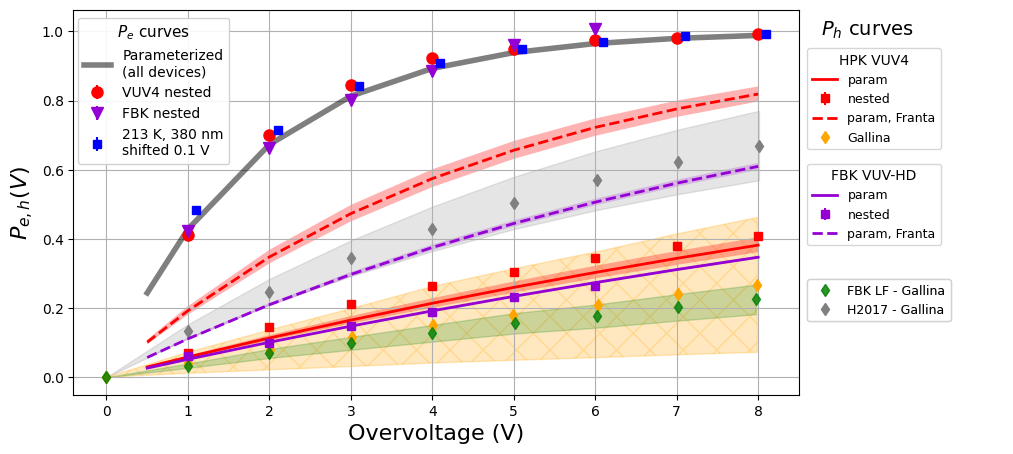

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
import matplotlib.gridspec as gridspec

# fig, ax = plt.subplots(1, 1, figsize=(8, 5))

fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[4, 1], wspace=0.05)

ax = fig.add_subplot(gs[0])
legAx = fig.add_subplot(gs[1])
legAx.axis('off')  # Hide the legend axis


parLine = "-"
nestedLine = "--"

vuv4Col = ms.red.col
fbkCol = ms.lxe.col

#### Ph - giacomo paper ####
h_ph_h2017, = ax.plot(ph_h2017[0], ph_h2017[1], marker="d", linestyle="none", label='H2017 - Gallina', color="gray")
ax.fill_between(ph_h2017[0], ph_h2017[1]*(1-errPh_H), ph_h2017[1]*(1+errPh_H), alpha=0.2, edgecolor="none", color="gray")

h_ph_vuv4, = ax.plot(ph_vuv4[0], ph_vuv4[1], marker="d", linestyle="none", label='Gallina', color="orange")
ax.fill_between(ph_vuv4[0], ph_vuv4[1]*(1-errPh_VUV4), ph_vuv4[1]*(1+errPh_VUV4), hatch = "x", alpha=0.25, edgecolor="none", color="orange")

h_ph_fbklf, = ax.plot(ph_fbklf[0], ph_fbklf[1], marker="d", linestyle="none", label='FBK LF - Gallina', alpha = 0.8, color="green")
ax.fill_between(ph_fbklf[0], ph_fbklf[1]*(1-errPh_FBKL), ph_fbklf[1]*(1+errPh_FBKL), alpha=0.2, edgecolor="none", color="green")

#### 
## HPK - parameterized
h_vuv4_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_vuv_defg[0], 1.0), label='param', color=vuv4Col, linewidth=2, linestyle=parLine)
ax.fill_between(x, ME.Pcar_parametrized(x, vh_vuv_defg[0]-vh_vuv_defg[1], 1.0), ME.Pcar_parametrized(x, vh_vuv_defg[0]+vh_vuv_defg[1], 1.0), alpha=0.3, color=vuv4Col, edgecolor="none")

## HPK nested
h_vuv4_nested = ax.errorbar(df_vuv4_def_nested['overvoltage'].values, df_vuv4_def_nested['ph'].values, yerr=df_vuv4_def_nested['errph'].values, color=vuv4Col, marker="s", linestyle="none", label='nested')

## ignore Franta HPK nested
# h_vuv4_franta_nested= ax.errorbar(df_vuv4_franta_nested['overvoltage'].values, df_vuv4_franta_nested['ph'].values, yerr=df_vuv4_franta_nested['errph'].values, marker="x", linestyle="none", color=vuv4Col, label='VUV4 nested, Franta')

## Franta parameterized
h_vuv4_franta_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_vuv_frantag[0], 1.0), linestyle=nestedLine, linewidth=2, label='param, Franta', color=vuv4Col)
ax.fill_between(x, ME.Pcar_parametrized(x, vh_vuv_frantag[0]-vh_vuv_frantag[1], 1.0), ME.Pcar_parametrized(x, vh_vuv_frantag[0]+vh_vuv_frantag[1], 1.0), alpha=0.3, color=vuv4Col, edgecolor="none")

#### FBK - parameterized
h_fbk_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_fbk_defg[0], 1.0), label='param', color=fbkCol, linewidth=2, linestyle=parLine)
ax.fill_between(x, ME.Pcar_parametrized(x, vh_fbk_defg[0]-vh_fbk_defg[1], 1.0), ME.Pcar_parametrized(x, vh_fbk_defg[0]+vh_fbk_defg[1], 1.0), alpha=0.2, color=fbkCol, edgecolor="none")

## FBK Parametrized franta
h_fbk_franta_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_fbk_frantag[0], 1.0), label='param, Franta', color=fbkCol, linewidth=2, linestyle=nestedLine)
ax.fill_between(x, ME.Pcar_parametrized(x, vh_fbk_frantag[0]-vh_fbk_frantag[1], 1.0), ME.Pcar_parametrized(x, vh_fbk_frantag[0]+vh_fbk_frantag[1], 1.0), alpha=0.2, color=fbkCol, edgecolor="none")

## FBK nested
h_fbk_nested = ax.errorbar(df_fbk_def_nested['overvoltage'].values, df_fbk_def_nested['ph'].values, yerr=df_fbk_def_nested['errph'].values, marker="s", linestyle="none", label='nested', color=fbkCol)

# ax.plot(df_fbk_franta_nested['overvoltage'].values, df_fbk_franta_nested['ph'].values, marker="s", linewidth=4, label='FBK franta global nested')
# h_fbk_franta_nested = ax.errorbar(df_fbk_franta_nested['overvoltage'].values, df_fbk_franta_nested['ph'].values, yerr=df_fbk_franta_nested['errph'].values, marker="X", markersize = 6, linestyle="none", color=fbkCol, label='nested, Franta')

handles = [h_vuv4_par, h_vuv4_nested, h_vuv4_franta_par, h_ph_vuv4,
          h_fbk_par, h_fbk_nested, h_fbk_franta_par,
          h_ph_fbklf, h_ph_h2017]
names = [h.get_label() for h in handles]

######### Pe curves #########
## parameterized
ppe_vuvPar, = ax.plot(x, ME.Pcar_parametrized(x, ve_vuv_defg[0], 1.0), linewidth=4, alpha = 0.5, label='Parameterized\n(all devices)', color = 'k')


# ppe_vuvPar_franta, = ax.plot(x, ME.Pcar_parametrized(x, ve_vuv_frantag[0], 1.0), label='VUV4 par, Franta', color = ms.cf4.col) ## identical to above
# ppe_fbkPar = ax.plot(x, ME.Pcar_parametrized(x, ve_fbk_defg[0], 1.0), label='FBK default par')

## nested
ppe_vuvNest = ax.errorbar(df_vuv4_def_nested['overvoltage'].values, df_vuv4_def_nested['pe'].values, yerr=df_vuv4_def_nested['errpe'].values, markersize = 8, marker="o", linestyle = "None", color = ms.red.col, label='VUV4 nested')
ppe_fbkNest = ax.errorbar(df_fbk_def_nested['overvoltage'].values, df_fbk_def_nested['pe'].values, yerr=df_fbk_def_nested['errpe'].values, marker="v", linestyle = "None", markersize = 8, color = ms.lxe.col, label='FBK nested')

# ppe_fbkNest_franta = ax.errorbar(df_fbk_franta_nested['overvoltage'].values, df_fbk_franta_nested['pe'].values, yerr=df_fbk_franta_nested['errpe'].values, marker="X", markersize = 6, linestyle = "None", label='FBK nested, Franta')

## 380 nm independent
# ppeHarry = ax.errorbar(harryVoltagePE[:-1], harryPe[:-1], harryPe[:-1]*0.01, linestyle="--", label='380 nm, 183K')
xPeShift = 0.1
ppe213 = ax.errorbar(np.array(overvoltage_213k[:-1])+xPeShift, np.array(pa_213k[:-1]), yerr=pa_error_213k[:-1], linestyle='None', marker = "s", color = 'b', label='213 K, 380 nm\nshifted 0.1 V')

# ppe_fbkPar_Seq, = ax.plot(x, ME.Pcar_parametrized(x, 1.57, 1.0), linewidth=3, alpha = 0.8, label='FBK UV (param)', color = 'royalblue')

peHandles = [ppe_vuvPar, ppe_vuvNest, ppe_fbkNest, ppe213] #, ppe_fbkNest_franta], ppe_fbkPar_Seq
peNames = [h.get_label() for h in peHandles]

# xSpot = -0.3
# # xSpot = 8
# ySpot = 1.03
# legend1 = legAx.legend(handles=handles[:4], labels=names[:4], loc='upper left', bbox_to_anchor=(xSpot, ySpot), fontsize=9, ncol=1, frameon=True, borderaxespad=0., title = "HPK VUV4", bbox_transform=ax.transData)
# legend2 = legAx.legend(handles=handles[4:8], labels=names[4:8], loc='upper left', bbox_to_anchor=(xSpot + 2.2, ySpot) , fontsize=9, ncol=1, frameon=True, borderaxespad=0., title = "FBK HD3", bbox_transform=ax.transData)
# legend3 = legAx.legend(handles=handles[8:], labels=names[8:], loc='upper left', bbox_to_anchor=(xSpot, ySpot - 0.3), fontsize=9, ncol=1, frameon=True, borderaxespad=0., bbox_transform=ax.transData)
# legend4 = legAx.legend(handles=peHandles, labels=peNames, loc='upper left', bbox_to_anchor=(xSpot, ySpot - 0.5), fontsize=9, ncol=1, frameon=True, borderaxespad=0., title = "PE curves", bbox_transform=ax.transData)

xSpot = -0.08
legend1 = legAx.legend(handles=handles[:4], labels=names[:4], loc='upper left', title = "HPK VUV4", fontsize=9, ncol=1, frameon=True, borderaxespad=0., bbox_to_anchor=(xSpot, 0.9), bbox_transform=legAx.transData)
legend2 = legAx.legend(handles=handles[4:7], labels=names[4:7], loc='upper left', title = "FBK VUV-HD", fontsize=9, ncol=1, frameon=True, borderaxespad=0., bbox_to_anchor=(xSpot, 0.6), bbox_transform=legAx.transData)
legend3 = legAx.legend(handles=handles[7:], labels=names[7:], loc='upper left', fontsize=9, ncol=1, frameon=True, borderaxespad=0., bbox_to_anchor=(xSpot, 0.3), bbox_transform=legAx.transData)
legAx.text(0.25, 0.92, r"$P_h$ curves", ha='center', va='bottom',
    fontsize=14, transform=legAx.transData,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.3')
)

legend4 = ax.legend(handles=peHandles, labels=peNames, loc='upper left', framealpha=0.9, title = r"$P_e$ curves", fontsize=10, title_fontsize=11, ncol=1, frameon=True, borderaxespad=0., bbox_to_anchor=(-0.35, 1.04), bbox_transform=ax.transData)

# Add all legends to the axes
legAx.add_artist(legend1)
legAx.add_artist(legend2)
legAx.add_artist(legend3)
# ax.add_artist(legend2)
# ax.add_artist(legend3)
# ax.add_artist(legend4)

ax.set_xlabel('Overvoltage (V)', fontsize=16)
ax.set_ylabel(r'$P_{e, h}(V)$', fontsize=16)

ax.grid()
# fig.tight_layout()